In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

3.11.2 0.13.2


In [4]:
df = pd.read_csv(
    "customs_features.csv",
    parse_dates=["entry_date", "accepted_date", "release_date"],
    dtype={"hs_code": str},
)
df.shape 

(4746, 35)

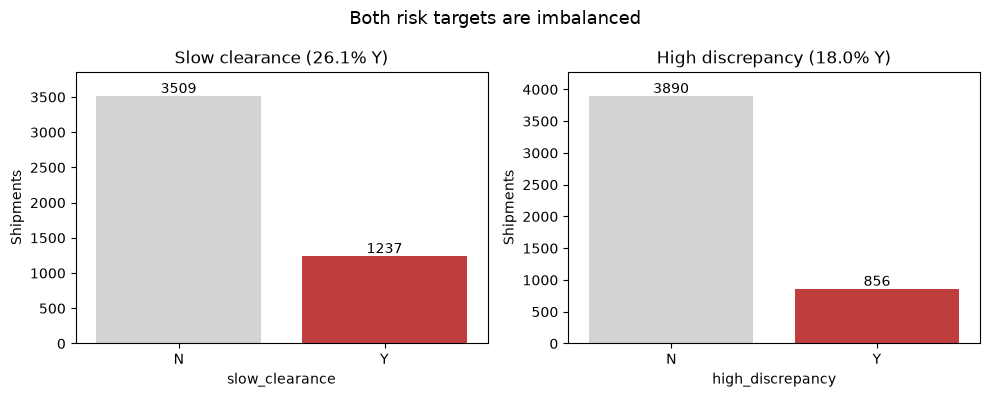

In [13]:
# CHART ONE

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=df, x='slow_clearance', ax=axes[0], order=['N', 'Y'],
              hue='slow_clearance', hue_order=['N', 'Y'],
              palette={'N': 'lightgrey', 'Y': 'tab:red'}, legend=False)

sns.countplot(data=df, x='high_discrepancy', ax=axes[1], order=['N', 'Y'],
              hue='high_discrepancy', hue_order=['N', 'Y'],
              palette={'N': 'lightgrey', 'Y': 'tab:red'}, legend=False)

axes[0].set_title("Slow clearance (26.1% Y)")
axes[0].set_xlabel("slow_clearance")
axes[0].set_ylabel("Shipments")

axes[1].set_title("High discrepancy (18.0% Y)")
axes[1].set_xlabel("high_discrepancy")
axes[1].set_ylabel("Shipments")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)
    ax.margins(y=0.1)     

fig.suptitle("Both risk targets are imbalanced", fontsize=13)
plt.tight_layout()
plt.savefig("images/01_target_balance.png", dpi=150, bbox_inches="tight")
plt.show()


In [14]:
df['gap_pct']

0       0.021145
1       0.040518
2      -0.034004
3      -0.037384
4      -0.040090
          ...   
4741    0.309286
4742    0.031111
4743   -0.029666
4744   -0.001118
4745    0.500000
Name: gap_pct, Length: 4746, dtype: float64

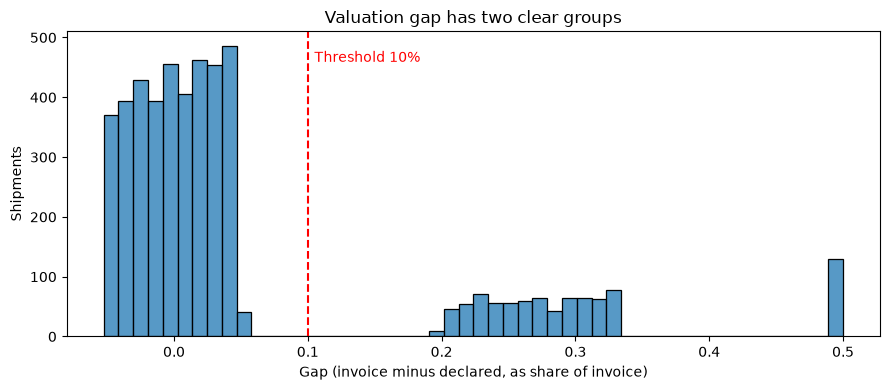

In [16]:
# CHART TWO
# Analysis of the Gap Percentage

plt.figure(figsize=(9, 4))

sns.histplot(data=df, x="gap_pct", bins=50, color="tab:blue")
plt.axvline(0.10, linestyle="--", color="red")
plt.text(0.105, plt.ylim()[1] * 0.9, "Threshold 10%", color="red")

plt.title("Valuation gap has two clear groups")
plt.xlabel("Gap (invoice minus declared, as share of invoice)")
plt.ylabel("Shipments")

plt.tight_layout()
plt.savefig("images/02_gap_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
(df["gap_pct"].round(3) == 0.5).sum()

np.int64(129)

In [ ]:
df.groupby(df["gap_pct"].round(3) == 0.5)["slow_clearance"].value_counts(normalize=True)

gap_pct  slow_clearance
False    N                 0.739658
         Y                 0.260342
True     N                 0.728682
         Y                 0.271318
Name: proportion, dtype: float64

In [21]:
# CHART THREE
# slow rate by port

port_rates = (
    df.assign(slow_flag=df["slow_clearance"] == "Y")
      .groupby("port_of_entry")
      .agg(rows=("shipment_id", "count"), slow_rate=("slow_flag", "mean"))
      .sort_values("slow_rate", ascending=False)
      .reset_index()
)
port_rates

,port_of_entry,rows,slow_rate
0,ALEXANDRIA,701,0.335235
1,MOMBASA,719,0.307371
2,LAGOS,701,0.306705
3,CASABLANCA,743,0.301480
4,MOMBASA ICD,231,0.207792
5,DURBAN,255,0.196078
6,TEMA,258,0.193798
7,DAR ES SALAAM,227,0.189427
8,PORT ELIZABETH,239,0.188285
9,NAIROBI,203,0.182266


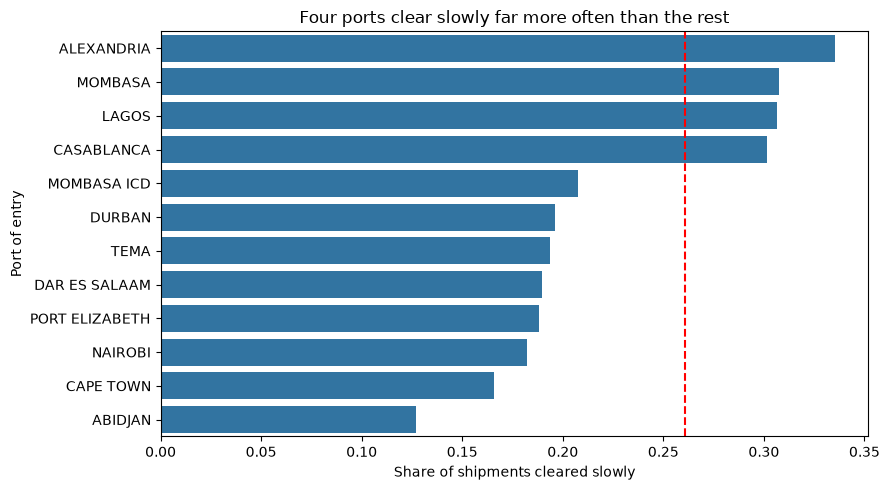

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(data=port_rates, x="slow_rate", y="port_of_entry", color="tab:blue")
plt.axvline(0.261, linestyle="--", color="red")

plt.title('Four ports clear slowly far more often than the rest')
plt.xlabel("Share of shipments cleared slowly")
plt.ylabel("Port of entry")

plt.tight_layout()
plt.savefig("images/03_slow_rate_by_port.png", dpi=150, bbox_inches="tight")
plt.show()